In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
from matplotlib.font_manager import FontProperties
import pickle
import math
import scipy
import scipy.signal
import vector
import json
import zipfile
import os

%matplotlib inline 
#np.set_printoptions(threshold=np.inf)

# pd.set_option('display.max_columns', None) #原来中间会有部分列的显示被省略

小仪器数据处理文件

In [2]:
def filters_main(spec,use_new=2):
    #comprehensive filters that handle the filter process
    #set use_new to 0 if use movemean 20pt, use_new to 1 if fir

    ## baseline 1
    # old mov_mean does not use
    # 输入一个list
    spec=np.array(spec)#转化成numpy形式
    if use_new == 1 or use_new == 2:
        baseline_1 = spec
    else:
        baseline_1 = spec

    ## filter
    if use_new == 2:
        filtered = filter_gaus(baseline_1)
    elif use_new == 0:
        # default 21pt filter
        filtered = filter_mov(baseline_1)

    ## baseline correction2
    if use_new == 1 or use_new == 2:
        out = filtered - matlab_percentile(filtered, 10)
        out[out < 0] = 0
    elif use_new == 0:
        filtered[filtered < 0] = 0
        out = filtered - filtered.min()

    out = out.tolist()
    #print(type(out)) = list
    #print(out) = []
    return(out)

def filter_gaus(input_spec,cycle=1):

    window = 100
    alpha = 6
    std = (window - 1) / (2 * alpha)
    b = scipy.signal.windows.gaussian(window, std, sym=True)
    b = b / sum(b)
    output_spec = np.convolve(input_spec, b,'same')
    for i in range(2, cycle + 1):
        output_spec = np.convolve(input_spec, b,'same')
    return(output_spec)



def filter_mov(input_spec, window=21, cycle=1):
    # input_spec is a 1d array
    # window is the width of the move mean
    # cycle is the repetive number
    use_old = 1
    if use_old != 0:
        MEAN_SIZE = window - 1
        for k in range(1,cycle+1):
            half = MEAN_SIZE/ 2
            npt=MEAN_SIZE+1
            lentmp1=len(input_spec)
            if half < 1:
                tmp =input_spec
            else:
                tmp=[]
                for i in range(0,lentmp1):
                    if i>=0 and i<=half-1 or i>=lentmp1-half-1 and  i<=lentmp1-1:
                        mean_value=math.floor(np.mean(input_spec[0:10]))
                        tmp.append((input_spec[i]-mean_value)/npt+mean_value)
                    else:
                        tmp.append(math.floor(np.mean(input_spec[i-10-1:i+10])))

                tmp = np.array(tmp)
            tmp=np.transpose(tmp)
            output_spec=tmp
    else:

        b = (1 / window) * np.ones(window)
        output_spec=np.convolve(input_spec,b,'same')
        for i in range(2,cycle+1):
            output_spec=np.convolve(input_spec,b,'same')

    return(output_spec)




def matlab_percentile(x, p):
    p = np.asarray(p, dtype=float)
    n = len(x)
    p = (p-50)*n/(n-1) + 50
    p = np.clip(p, 0, 100)
    baseline=np.percentile(x, p)
    return(baseline)

def get_spec_params(data,is_neg=0):
# is_neg=0时：正模式，输入一个参数正模式
    if is_neg: #负模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['calib_mass_start']['value']
    else: #正模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['calib_mass_start']['value']

    return(mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start)

def Method1_get_filelist(path): #path = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/20PPM/'  # (一个文件夹)
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if 'mrz' in file:
                file_list.append(os.path.join('%s%s' % (root, file)))
  # file_list 是一个list
    return(file_list)
def load_mrz(name):  #filepath = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/500PPB/1.mrz' , type=mrz
    zfile = zipfile.ZipFile(name)   #zfile.namelist()={'arbitrary_2021_10_30_18_07_11_227.json'}
    if len(zfile.namelist()) ==1:
        for filenames in zfile.namelist():
            zfile.extract(filenames, path=os.getcwd())
            file = os.getcwd() + '/' + filenames
            with open(file, "r", encoding='utf-8') as fp:
                data = json.load(fp)
            if os.path.exists(file):  # 如果文件存在
                os.remove(file)
        return(data)
    
def process_mrz_data(data,use_new_filter=2):
    n=0
    while n<=(len(data['analysis']['scan_list'])-1):
        pt_per_th = data['analysis']['parameters_files']['static_parameters']['static_parameters']['pt_per_th']
        scan_speed = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['calib_parameters']['scan_speed']['value']
        if data['analysis']['scan_list'][n]['method_parameters']['polarity'] == "NEG":
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data, 1)
        else:
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data)

        if type(data['analysis']['scan_list'][n]['raw_data'][0])== "dict":
            print('data是字典结构，请重新调试程序')
            #data['analysis']['scan_list'][n]['filtered']={}
            data['analysis']['scan_list'][n]['mz'] = {}
            for len_data in range(0,len(data['analysis']['scan_list'][n]['data'])):
                if len(data['analysis']['scan_list'][n]['data'][0])==1:
                    if data['analysis']['scan_list'][n].__contains__('raw_counting_data') and data['analysis']['scan_list'][n].__contains__('raw_analog_data'):
                        # filtered the analog data
                        data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_analog_data'][0],use_new_filter)
                        data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]


                if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                    x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

                else:
                    x0=[i for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]


                # prepare the temp
                if data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c0') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c1') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c2') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('current_temperature') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('calib_temperature'):
                    if float(data['analysis']['config']['DataProcessing']['mass_temp_comp_enabled']) == 1:
                        t_c0 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c0']
                        t_c1 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c1']
                        t_c2 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c2']
                        dt = data['analysis']['scan_list'][n]['spec_parameters']['current_temperature'] - data['analysis']['scan_list'][n]['spec_parameters']['calib_temperature']

                        data['analysis']['scan_list'][n]['mz'] = temp_correction(data['analysis']['scan_list'][n]['mz'],t_c0, t_c1, t_c2, dt)
                        data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

        else:
            data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_data'], 2)
            data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]
            #prepare the mz
            len_data=len(data['analysis']['scan_list'][n]['raw_data'])
            if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
            else:
                x0=[i for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
        n=n+1
    return(data)
                                                        
                                                          
def baseline_delete_method2(raw_data_list):   #所有的数据 按照平均值的正负3倍std,速度很慢
    spec = np.array(raw_data_list)
    baseline = spec
    i = 0
    mean_base=[]
    std_base=[]
    while i < 3 :
        mean_base.append(np.mean(baseline))
        std_base.append(np.std(baseline))
        baseline = spec[np.where(spec<(mean_base[i] + 3*std_base[i]))]
        i = i+1
    if np.size(spec,0)==1:
        filterd_data = spec - np.mean(baseline) # [[class 'numpy.ndarray']]
    else:
        print('请检查raw_data维数')
    return (filterd_data) ## <class 'numpy.ndarray'>

读一张小仪器质谱图

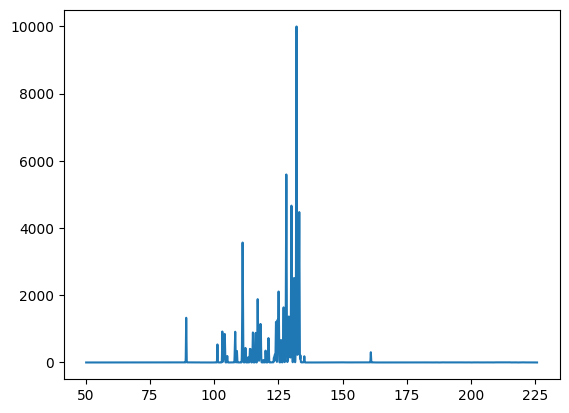

In [3]:
path = 'D:/DATA/ZHY/cwt图像处理/2hg/'
file_list = Method1_get_filelist(path)
y_int=[]
x_mz=[]
from scipy.linalg import expm,logm
for name in file_list:
#     print(name)
    data = load_mrz(name)
#     print(len(data['analysis']['scan_list'][0]['raw_data']))
    data =process_mrz_data(data, use_new_filter=2)
    dot_len = np.size(data['analysis']['scan_list'][0]['mz'])
    y_int.append(data['analysis']['scan_list'][0]['analog_filtered'][0])
    x_mz.append(data['analysis']['scan_list'][0]['mz'][0])

plt.plot(x_mz[1],y_int[1])
plt.savefig('plot2.svg', format='svg')
plt.show()

CWT 尺度设置参数定义

In [4]:
type(x_mz[0])
spectrogram=np.array([x_mz[0],y_int[0]])
spectrogram

list

array([[ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ]])

In [ ]:
min_width = 1
max_width = 100
num_scales = 10

<Figure size 1000x600 with 0 Axes>

Text(0.5, 0, 'Time')

Text(0, 0.5, 'Scale')

Text(0.5, 1.0, 'Continuous Wavelet Transform Spectrogram')

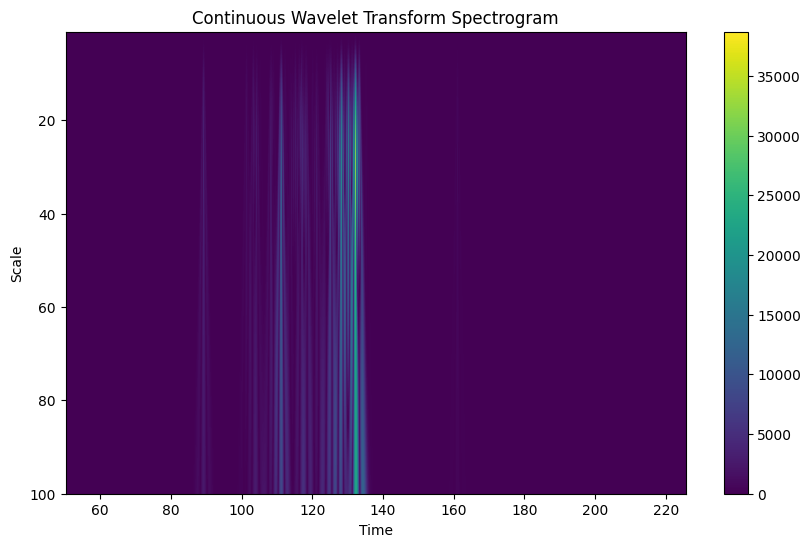

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal


spectrogram=np.array([x_mz[1],y_int[1]])
# 信号强度
signal_strength = spectrogram[1]

# 连续小波变换参数
wavelet = signal.ricker
widths = np.arange(1, 100)  # 尺度范围

# 进行连续小波变换
cwt_matrix = signal.cwt(signal_strength, wavelet, widths)

# 获取时间轴和频率轴
time = spectrogram[0]
freq = 1 / widths[::-1]

# 绘制时频图
plt.figure(figsize=(10, 6))
plt.imshow(np.abs(cwt_matrix), extent=[time.min(), time.max(),100,1],  aspect='auto', vmin=abs(cwt_matrix).min(), vmax=abs(cwt_matrix).max())
plt.colorbar()
plt.xlabel('Time')
plt.ylabel('Scale')
plt.title('Continuous Wavelet Transform Spectrogram')
plt.show()

In [16]:
np.shape(np.abs(cwt_matrix))

(200, 18229)

In [6]:
np.abs(cwt_matrix)

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [4.48709835, 4.47527344, 4.46233843, ..., 5.25728785, 5.40634583,
        5.55318608],
       [4.49542436, 4.48281225, 4.46910866, ..., 5.18176033, 5.33104495,
        5.47817847],
       [4.50347195, 4.49010129, 4.47565697, ..., 5.10730253, 5.25674327,
        5.40409807]])

In [7]:
max_value = np.max(np.abs(cwt_matrix))
max_value
max_row, max_col = np.unravel_index(np.argmax(np.abs(cwt_matrix)), np.abs(cwt_matrix).shape)
max_row, max_col


38708.87317336493

(25, 8505)

In [8]:
min_width = 1
max_width = 100
num_scales = [40,50,60,70,80,90,100,120,130,150,200]



<Figure size 1000x600 with 0 Axes>

Text(0.5, 0, 'Time')

Text(0, 0.5, 'Scale')

Text(0.5, 1.0, 'Continuous Wavelet Transform Spectrogram')

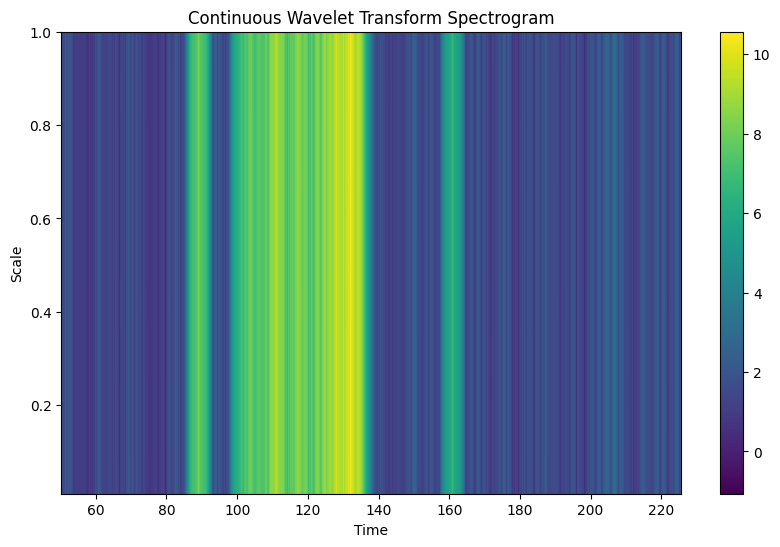

In [10]:

value=[]
for i in num_scales:
    widths=np.linspace(min_width, max_width, i)
    cwt_matrix = signal.cwt(signal_strength, wavelet, widths)
    value.append(np.amax(np.abs(cwt_matrix), axis=0))

plt.figure(figsize=(10, 6))
plt.imshow(np.log(np.array(value)),extent=[time.min(), time.max(),freq.min(),freq.max()],  aspect='auto')
plt.colorbar()
plt.xlabel('Time')
plt.ylabel('Scale')
plt.title('Continuous Wavelet Transform Spectrogram')
plt.savefig('plot3.svg', format='svg')
plt.show()

array([38701.68204864, 38680.21792989, 38701.64977035, 38685.97671192,
       38713.70223722, 38695.89014442, 38708.87317336, 38697.43105521,
       38684.24283777, 38712.40589302, 38711.23636428])

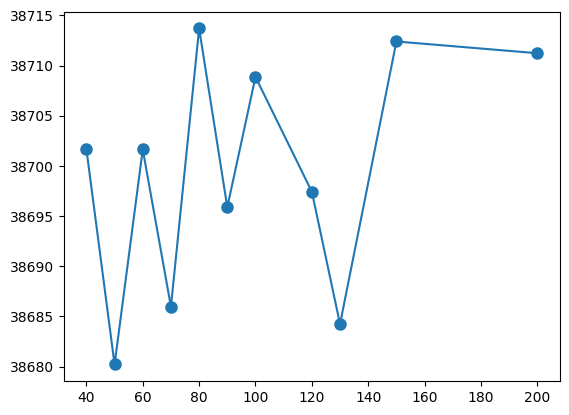

In [11]:
value2=np.array(value)[:,max_col]
value2

plt.plot(num_scales,value2,marker='o', markersize=8)
plt.savefig('plot4.svg', format='svg')

array([[ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143],
       [ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143],
       [ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143],
       ...,
       [ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143],
       [ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143],
       [ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
        225.65594508, 225.66557143]])

array([[ 40,  40,  40, ...,  40,  40,  40],
       [ 50,  50,  50, ...,  50,  50,  50],
       [ 60,  60,  60, ...,  60,  60,  60],
       ...,
       [130, 130, 130, ..., 130, 130, 130],
       [150, 150, 150, ..., 150, 150, 150],
       [200, 200, 200, ..., 200, 200, 200]])

array([ 50.23464505,  50.2442672 ,  50.25388936, ..., 225.64631872,
       225.65594508, 225.66557143])

array([ 40,  40,  40, ..., 200, 200, 200])

D:\Software\Anaconda3\lib\site-packages\matplotlib\collections.py:996: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


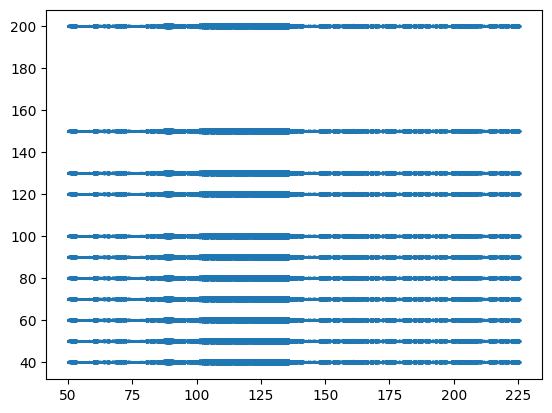

In [12]:
X, Y = np.meshgrid(time , num_scales)
X
Y
X = X.flatten()
Y = Y.flatten()
X
Y
plt.scatter(X, Y, s=np.log(np.array(value)),marker="o")